In [23]:
import numpy as np
import seaborn as sns # optional
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib

In [3]:
sns.set_context('talk')

In [4]:
%matplotlib widget

Google Earth section


I first started by identifing the pixel resolution in meters, using one of the images as sample

In [ ]:
sample = mpimg.imread('sentinel-data/White_light/2020Nov.jpg')
fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(sample)
plt.show()

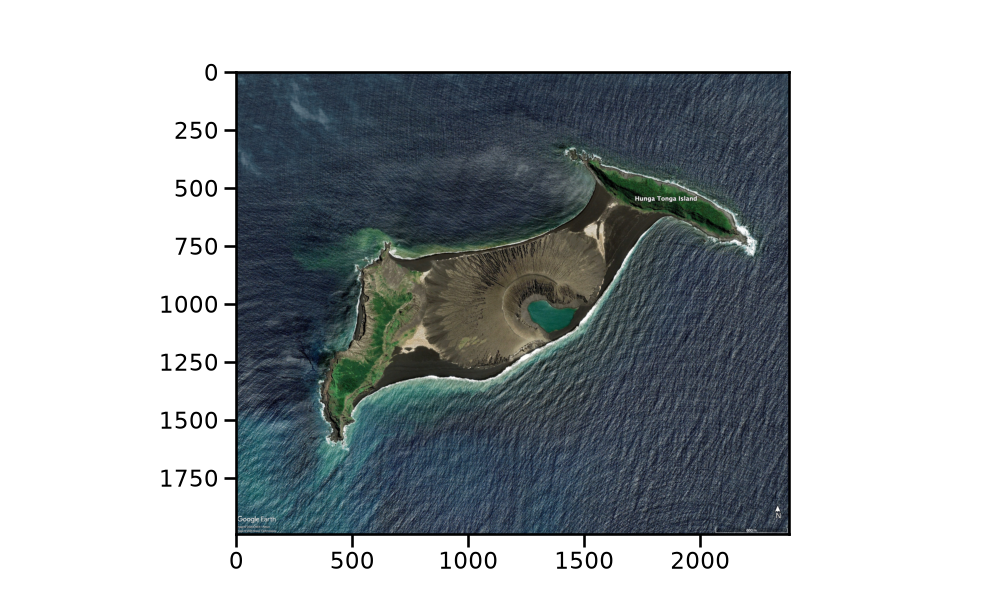

In [ ]:
pixel_m2 = (600/ (2375.3 - 2067.8))**2
print(pixel_m2)

From here I identified the area in m^2 for the Google Earth images of ~ 3.81 m^2 per pixel

Afterward, I plotted the differences between channels of the sample, to identify the best one to compute the land area over time

In [ ]:
cr = sample[:, :, 0]
cg = sample[:, :, 1]
cb = sample[:, :, 2]
rg_diff = cr - cg
rb_diff = cr  - cb
gb_diff = cg - cb

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(10, 6))
ax1.imshow(rg_diff)
ax2.imshow(rb_diff)
ax3.imshow(gb_diff)
plt.show()


Selection deleted
fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(10, 6))
ax1.imshow(rg_diff)
ax2.imshow(rb_diff)
ax3.imshow(gb_diff)
plt.show()
Figure 11
Of the 3 differences, the Green-Blue channel seems to be the one to include the most of the land area, including the vegetation (which the Red-Blue difference exclude)

Once I defined this, I expanded the computation to all the images, to ensure that the images are all behaving in the same way.

In [ ]:
here = pathlib.Path('.')

In [ ]:
wl_files = list((here / 'sentinel-data/White_light').rglob('*.jpg'))
print(wl_files)

In [ ]:
for file in wl_files:
    wl = mpimg.imread(file)
    cr = wl[:, :, 0]
    cg = wl[:, :, 1]
    cb = wl[:, :, 2]
    rg_diff = cr - cg
    rb_diff = cr  - cb
    gb_diff = cg - cb
    fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(10, 6))
    ax1.imshow(rg_diff)
    ax2.imshow(rb_diff)
    ax3.imshow(gb_diff)
    plt.show()

With the output of the previous function, I observed that the images from Dec 2021 and Jan 2022 are not viable to be analysed, due to a lot of clouds confusing the analysis, so I later excluded them from the land vs time analysis.

I then proceeded to write a function to compute the total land area over time, create a plot to visualize the change, and save the plot in the processed data

In [ ]:
def land_over_time(wl_images, dates):
    """
    This function takes the list containing the white light (Google Earth)
    images, and the labels of the dates when the images were taken, computes 
    the total land area in the image, and returns a scatter plot of the land 
    area as a function of time.
    """
    total_land_area = []
    for file in wl_images:
        wl = mpimg.imread(file)
        cr = wl[:, :, 0]
        cg = wl[:, :, 1]
        cb = wl[:, :, 2]
        rg_diff = cr - cg
        rb_diff = cr  - cb
        gb_diff = cg - cb
        pixel_area_m2 = (600 / (2375.3 - 2067.8)) ** 2
        land_pixels = gb_diff < 100
        total_land_pixel = np.sum(land_pixels)
        area_km2 = (total_land_pixel * pixel_area_m2) / 1000000
        total_land_area.append(area_km2)

    del total_land_area[3:5] # This line is to be modified 
                             # if the wl files are different
    plt.close('all')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(dates, total_land_area, marker='o', color='brown', linewidth=2.5, markersize=8)
    ax.set_title("Land area over time", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("Surface (km^2)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.savefig("sentinel-processed/land_vs_time.jpg", dpi=300, bbox_inches='tight')

In [ ]:
date_labels = ['2014-2', '2016-5', '2020-11', '2023-10']
land_over_time(wl_files, date_labels)

Now for the Sentinel 2 section

Here I first started by computing the pixel resolution in km^2, using a sample file at first

In [ ]:
file = 'sentinel-data/S2_2017-07-12/Sentinel-2_L2A_False_color.tiff'

In [44]:
with rasterio.open(file) as src:
    resolution = src.res
    bounds = src.bounds

In [ ]:
# Resolutions in angular fraction
res_x = resolution[0]
res_y = resolution[1]
length_p = np.abs(bounds.left-bounds.right) / res_x
height_p = np.abs(bounds.top-bounds.bottom) / res_y
print(f'The image is {length_p} by {height_p } pixels')

# Conversion from angle to kilometer
conv_const = 40075 / 360 # Using a mean value for the Earth 
                         # circumference in km^2, to convert
                         # the pixel reolution
res_x = res_x * conv_const
res_y = res_y * conv_const
lenght_m = length_p * res_x
height_m = height_p * res_y
image_area = lenght_m * height_m
print(f'The total area of the image is {image_area} km^2')

# Computed pixel area in m^2, to be compared
# to the expected one of 100 m^2
pixels = length_p * height_p
pixel_km2 = image_area / pixels
pixel_m2 = pixel_km2 * 1e6
print(pixel_m2)

The image is 529.0 by 314.0 pixels
The total area of the image is 15.565376776654007 km^2


After I computed the pixel area in km, I started to load the files to see how to compute the vegetation index

In [46]:
here = pathlib.Path('.')

In [47]:
files_2017 = list((here / 'sentinel-data/S2_2017-07-12').rglob('*.tiff'))
files_2018 = list((here / 'sentinel-data/S2_2018-07-12').rglob('*.tiff'))
files_2019 = list((here / 'sentinel-data/S2_2019-07-12').rglob('*.tiff'))

C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = rasterio.open(file_list[3]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:3: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = rasterio.open(file_list[7]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:4: RuntimeWarning: invalid value encountered in divide
  veg_ind =(b8 - b4) / (b8 + b4)


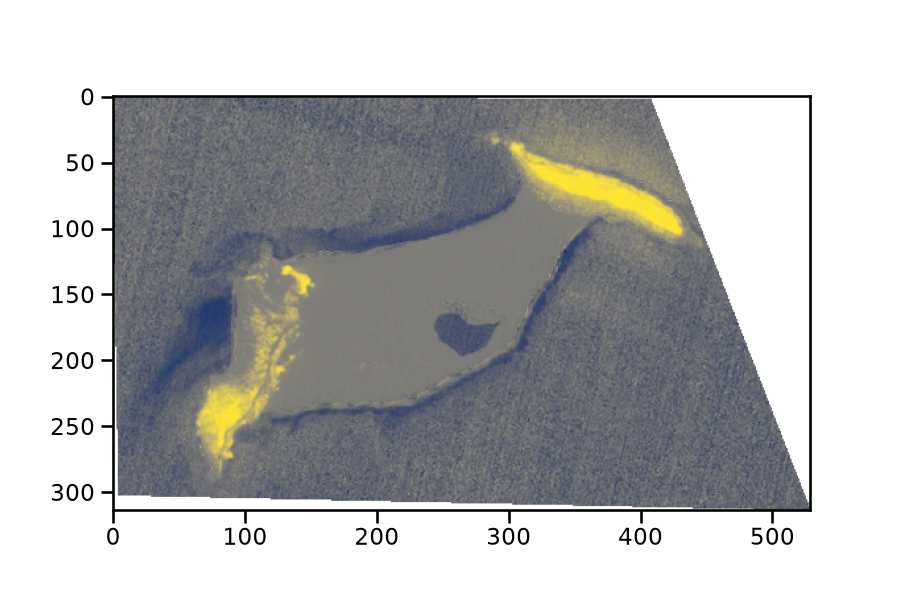

C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = rasterio.open(file_list[3]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:3: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = rasterio.open(file_list[7]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:4: RuntimeWarning: invalid value encountered in divide
  veg_ind =(b8 - b4) / (b8 + b4)


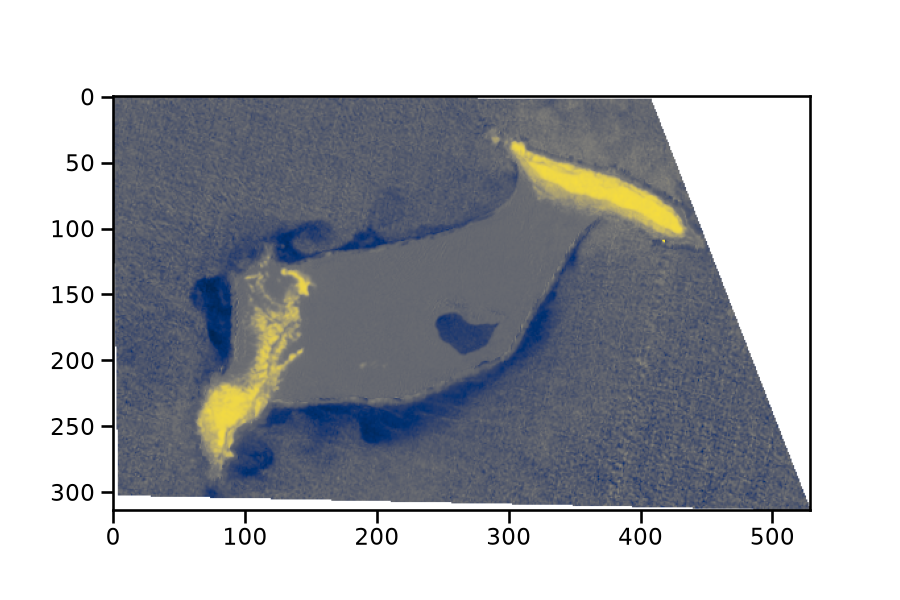

C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = rasterio.open(file_list[3]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:3: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = rasterio.open(file_list[7]).read(1)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:4: RuntimeWarning: invalid value encountered in divide
  veg_ind =(b8 - b4) / (b8 + b4)
C:\Users\march\AppData\Local\Temp\ipykernel_7812\2258330871.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To co

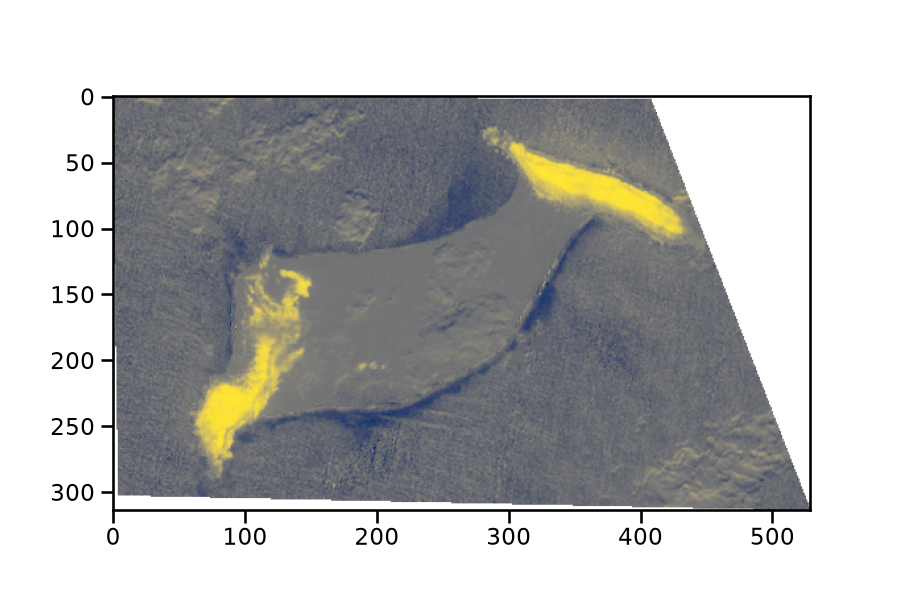

In [ ]:
def vegetation_plot(file_list):
    """
    This function takes the list of the tiff files,
    open the B4 and B8 files needed to compute the
    vegetation index, and plot the corresponding images
    """
    b4 = rasterio.open(file_list[3]).read(1)
    b8 = rasterio.open(file_list[7]).read(1)
    veg_ind =(b8 - b4) / (b8 + b4)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(veg_ind, cmap='cividis')
    plt.show()

vegetation_plot(files_2017)
vegetation_plot(files_2018)
vegetation_plot(files_2019)

C:\Users\march\AppData\Local\Temp\ipykernel_7812\3034825474.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b4 = src4.read(1).astype('float32')
C:\Users\march\AppData\Local\Temp\ipykernel_7812\3034825474.py:13: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b8 = src8.read(1).astype('float32')
C:\Users\march\AppData\Local\Temp\ipykernel_7812\3034825474.py:23: RuntimeWarning: invalid value encountered in divide
  veg_ind = (b8 - b4) / (b8 + b4)


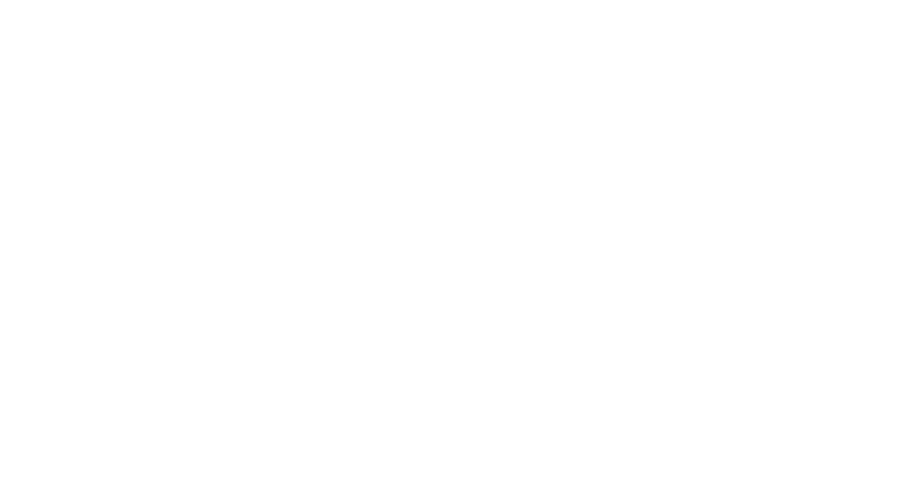

In [ ]:
def veg_over_time(files, dates):
    """
    This function takes the lists of Sentinel-2 files, and the labels
    of the date when the image was taken, compute the area of the islands
    covered in vegetation, returning a plot of the vegetation evolution over time.
    """
    veg_threshold = 0.3  
    total_veg_area = []
    for file_list in all_files:
        # For each of the year, open the necessery B4 and B8 files from the list
        with rasterio.open(file_list[3]) as src4, rasterio.open(file_list[7]) as src8:
            b4 = src4.read(1).astype('float32')
            b8 = src8.read(1).astype('float32')

            # Compute the pixel resolution
            res_x, res_y = src4.res
            conv_const = 40075 / 360
            res_x = res_x * conv_const
            res_y = res_y * conv_const
            pixel_area_km2 = res_x * res_y
            
        # Compute the vegetation index
        veg_ind = (b8 - b4) / (b8 + b4)
        veg_ind = np.nan_to_num(veg_ind, nan=-1.0) # Replace any nan value

        # Compute the vegetation area in km^2
        veg_pixels = veg_ind > veg_threshold
        total_veg_pixels = np.sum(veg_pixels)
        area_km2 = total_veg_pixels * pixel_area_km2
    
        # Save the area results to plot them
        total_veg_area.append(area_km2)

    plt.close('all')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(date_labels, total_veg_area, marker='o', color='green', linewidth=2.5, markersize=8)
    ax.set_title("Vegetation area over time", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("Surface (km^2)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.savefig("sentinel-processed/vegetation_vs_time.jpg", dpi=300, bbox_inches='tight')

In [ ]:
all_files = [sorted(files_2017), sorted(files_2018), sorted(files_2019)]
date_labels = ['2017-07-12', '2018-07-12', '2019-07-12']

veg_over_time(all_files, date_labels)